In [1]:
import pandas as pd
import numpy as np

In [2]:
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
data = pd.read_csv(r"C:\Users\shriy\OneDrive\Documents\summer research\zr7vgbcyr2-1\metadata.csv")

In [4]:
data.tail()

,patient_id,lesion_id,smoke,drink,background_father,background_mother,age,pesticide,gender,skin_cancer_history,...,diameter_2,diagnostic,itch,grew,hurt,changed,bleed,elevation,img_id,biopsed
2293,PAT_1708,3156,NaN,NaN,NaN,NaN,73,NaN,NaN,NaN,...,NaN,ACK,True,False,False,False,False,False,PAT_1708_3156_175.png,False
2294,PAT_46,880,False,False,POMERANIA,POMERANIA,55,False,FEMALE,True,...,12.0,BCC,True,True,False,True,False,False,PAT_46_880_140.png,True
2295,PAT_1343,1217,NaN,NaN,NaN,NaN,74,NaN,NaN,NaN,...,NaN,SEK,False,False,False,False,False,False,PAT_1343_1217_404.png,False
2296,PAT_326,690,False,False,POMERANIA,POMERANIA,58,True,FEMALE,True,...,4.0,BCC,True,False,False,False,False,True,PAT_326_690_823.png,True
2297,PAT_1714,3189,NaN,NaN,NaN,NaN,41,NaN,NaN,NaN,...,NaN,SEK,False,True,False,False,False,True,PAT_1714_3189_989.png,False


In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2298 entries, 0 to 2297
Data columns (total 26 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   patient_id           2298 non-null   object 
 1   lesion_id            2298 non-null   int64  
 2   smoke                1494 non-null   object 
 3   drink                1494 non-null   object 
 4   background_father    1480 non-null   object 
 5   background_mother    1476 non-null   object 
 6   age                  2298 non-null   int64  
 7   pesticide            1494 non-null   object 
 8   gender               1494 non-null   object 
 9   skin_cancer_history  1494 non-null   object 
 10  cancer_history       1494 non-null   object 
 11  has_piped_water      1494 non-null   object 
 12  has_sewage_system    1494 non-null   object 
 13  fitspatrick          1494 non-null   float64
 14  region               2298 non-null   object 
 15  diameter_1           1494 non-null   f

In [6]:
data["patient_id"].nunique()

1373

In [7]:
data["patient_id"].value_counts().head()

patient_id
PAT_388     10
PAT_645     10
PAT_330     10
PAT_53       7
PAT_1414     7
Name: count, dtype: int64

In [8]:
patient_counts = data['patient_id'].value_counts()

print(patient_counts.describe())
print(patient_counts.head(20))

count    1373.000000
mean        1.673707
std         1.115038
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max        10.000000
Name: count, dtype: float64
patient_id
PAT_388     10
PAT_645     10
PAT_330     10
PAT_53       7
PAT_1414     7
PAT_747      7
PAT_115      7
PAT_270      7
PAT_691      7
PAT_202      6
PAT_492      6
PAT_46       6
PAT_771      6
PAT_108      6
PAT_1364     6
PAT_93       6
PAT_38       6
PAT_677      6
PAT_267      6
PAT_63       6
Name: count, dtype: int64


In [9]:
data = data.sort_values(by = 'patient_id').reset_index(drop=True)

In [10]:
data

,patient_id,lesion_id,smoke,drink,background_father,background_mother,age,pesticide,gender,skin_cancer_history,...,diameter_2,diagnostic,itch,grew,hurt,changed,bleed,elevation,img_id,biopsed
0,PAT_10,18,True,False,GERMANY,GERMANY,69,False,MALE,False,...,9.0,SCC,True,UNK,False,UNK,False,True,PAT_10_18_830.png,True
1,PAT_100,393,False,False,POMERANIA,POMERANIA,14,False,MALE,False,...,3.0,NEV,False,False,False,False,False,False,PAT_100_393_595.png,True
2,PAT_100,393,False,False,POMERANIA,POMERANIA,14,False,MALE,False,...,3.0,NEV,False,False,False,False,False,False,PAT_100_393_898.png,True
3,PAT_1000,31,NaN,NaN,NaN,NaN,65,NaN,NaN,NaN,...,NaN,SEK,False,False,False,False,False,False,PAT_1000_31_620.png,False
4,PAT_1006,53,NaN,NaN,NaN,NaN,63,NaN,NaN,NaN,...,NaN,ACK,False,False,False,False,False,False,PAT_1006_53_716.png,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2293,PAT_998,17,NaN,NaN,NaN,NaN,50,NaN,NaN,NaN,...,NaN,SEK,False,True,False,False,False,False,PAT_998_17_641.png,False
2294,PAT_999,20,NaN,NaN,NaN,NaN,40,NaN,NaN,NaN,...,NaN,ACK,True,False,False,False,True,False,PAT_999_20_540.png,False
2295,PAT_999,20,NaN,NaN,NaN,NaN,40,NaN,NaN,NaN,...,NaN,ACK,True,False,False,False,True,False,PAT_999_20_583.png,False
2296,PAT_999,20,NaN,NaN,NaN,NaN,40,NaN,NaN,NaN,...,NaN,ACK,True,False,False,False,True,False,PAT_999_20_401.png,False


In [11]:
data["diagnostic"] = data["diagnostic"].replace({
    "BOD" : "SCC",
})

In [12]:
data["diagnostic"].value_counts()

diagnostic
BCC    845
ACK    730
NEV    244
SEK    235
SCC    192
MEL     52
Name: count, dtype: int64

In [13]:
diagnostic_counts = data["diagnostic"].value_counts()
diagnostic_counts

diagnostic
BCC    845
ACK    730
NEV    244
SEK    235
SCC    192
MEL     52
Name: count, dtype: int64

In [14]:
diagnosis_percentage = (
    data['diagnostic']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print(diagnosis_percentage)

diagnostic
BCC    36.77
ACK    31.77
NEV    10.62
SEK    10.23
SCC     8.36
MEL     2.26
Name: proportion, dtype: float64


Text(0.5, 1.0, 'Distribution of diagnostic classes')

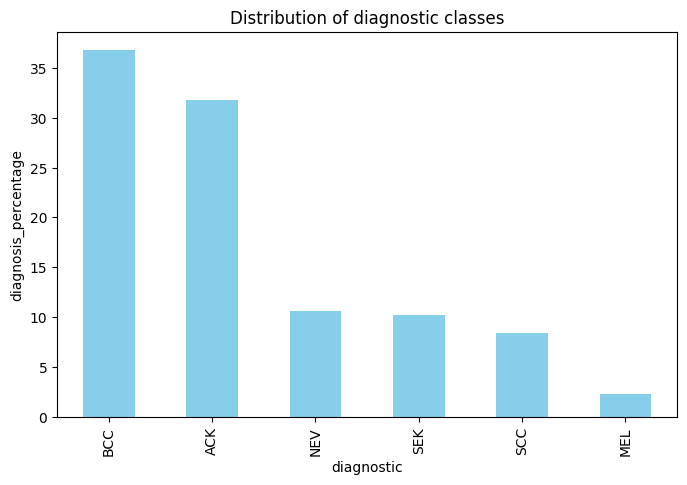

In [15]:
diagnosis_percentage.plot(
    kind = 'bar',
    figsize =(8,5),
    color='skyblue',
)
plt.xlabel("diagnostic")
plt.ylabel("diagnosis_percentage")
plt.title("Distribution of diagnostic classes")

In [16]:
data['diagnostic'].value_counts()

diagnostic
BCC    845
ACK    730
NEV    244
SEK    235
SCC    192
MEL     52
Name: count, dtype: int64

In [17]:
import pandas as pd
from scipy.stats import chi2_contingency

def chi_square_test(data, feature, target='diagnostic'):
    contingency = pd.crosstab(data[feature], data[target])
    chi2, p, dof, expected = chi2_contingency(contingency)
    
    # Cramér's V for effect size
    n = contingency.sum().sum()
    min_dim = min(contingency.shape) - 1
    cramers_v = (chi2 / (n * min_dim)) ** 0.5
    
    return {
        'feature': feature,
        'chi2': round(chi2, 2),
        'p_value': p,
        'cramers_v': round(cramers_v, 3),
        'significant': p < 0.05
    }

# list all your categorical features here
categorical_features = ['itch', 'grew', 'hurt', 'changed', 'elevation', 'bleed',
                         'cancer_history', 'skin_cancer_history', 'smoke', 'drink',
                         'background_father', 'background_mother', 'gender',
                         'region', 'pesticide', 'biopsed']  # keep biopsed in for now just to see, but don't use it as an input feature later

results = []
for feat in categorical_features:
    if feat in data.columns:
        results.append(chi_square_test(data, feat, target='diagnostic'))

results_df = pd.DataFrame(results).sort_values('cramers_v', ascending=False)
print(results_df)

                feature     chi2        p_value  cramers_v  significant
15              biopsed  1499.94   0.000000e+00      0.808         True
1                  grew   855.71  2.160752e-177      0.431         True
0                  itch   654.96  2.905929e-134      0.378         True
3               changed   653.57  5.783800e-134      0.377         True
4             elevation   651.17  1.885568e-133      0.376         True
5                 bleed   581.74  1.435794e-118      0.356         True
13               region   987.84  5.093887e-165      0.293         True
2                  hurt   374.50   2.495937e-74      0.285         True
14            pesticide    31.44   7.663615e-06      0.145         True
8                 smoke    29.43   1.910254e-05      0.140         True
10    background_father   104.46   3.331274e-04      0.119         True
11    background_mother    75.36   1.171644e-02      0.101         True
12               gender    12.22   3.194504e-02      0.090      

In [18]:
data['cancer_binary'] = data['diagnostic'].map({
    'BCC':'Cancer','SCC':'Cancer','MEL':'Cancer',
    'ACK':'Non-cancer','NEV':'Non-cancer','SEK':'Non-cancer'
})

for feat in ['cancer_history','skin_cancer_history']:
    ct = pd.crosstab(data[feat], data['cancer_binary'])
    chi2, p, dof, exp = chi2_contingency(ct)
    print(feat, 'p =', p)

cancer_history p = 0.8772859466160792
skin_cancer_history p = 0.1255592993129681


In [19]:
data['cancer_history'].value_counts(normalize=True)


cancer_history
True     0.521419
False    0.478581
Name: proportion, dtype: float64

In [20]:
from scipy.stats import kruskal

# split age values by diagnostic group
groups = [data[data['diagnostic'] == d]['age'].dropna() for d in data['diagnostic'].unique()]

stat, p_value = kruskal(*groups)
print(f"Kruskal-Wallis H-statistic: {stat:.2f}, p-value: {p_value}")

Kruskal-Wallis H-statistic: 480.77, p-value: 1.1272543664668308e-101


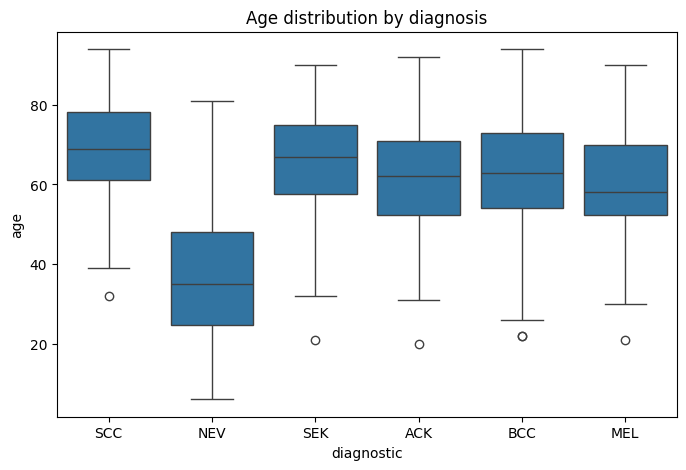

In [21]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
sns.boxplot(x='diagnostic', y='age', data=data)
plt.title('Age distribution by diagnosis')
plt.show()

In [22]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, accuracy_score

# your finalized features
features = ['grew', 'itch', 'changed', 'elevation', 'bleed', 'region', 'hurt', 'age']
target = 'diagnostic'

# patient-grouped split (avoid leakage)
patients = data['patient_id'].unique()
patients = np.asarray(patients)
train_patients, test_patients = train_test_split(patients, test_size=0.2, random_state=42)

train_df = data[data['patient_id'].isin(train_patients)].copy()
test_df = data[data['patient_id'].isin(test_patients)].copy()

# encode target
le = LabelEncoder()
train_df['target_enc'] = le.fit_transform(train_df[target])
test_df['target_enc'] = le.transform(test_df[target])

# one-hot encode categorical features (region, itch, grew, etc. if stored as strings/bools)
X_train = pd.get_dummies(train_df[features], dummy_na=True)
X_test = pd.get_dummies(test_df[features], dummy_na=True)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)  # align columns

y_train = train_df['target_enc']
y_test = test_df['target_enc']

print(X_train.shape, X_test.shape)

(1837, 40) (461, 40)


In [24]:
pip install xgboost 

   ---------------------------------------- 0.0/69.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/69.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/69.5 MB ? eta -:--:--
   ---------------------------------------- 0.3/69.5 MB ? eta -:--:--
   ---------------------------------------- 0.3/69.5 MB ? eta -:--:--
   ---------------------------------------- 0.3/69.5 MB ? eta -:--:--
   ---------------------------------------- 0.3/69.5 MB ? eta -:--:--
   ---------------------------------------- 0.5/69.5 MB 374.3 kB/s eta 0:03:05
   ---------------------------------------- 0.5/69.5 MB 374.3 kB/s eta 0:03:05
   ---------------------------------------- 0.5/69.5 MB 374.3 kB/s eta 0:03:05
   ---------------------------------------- 0.8/69.5 MB 375.3 kB/s eta 0:03:04
   ---------------------------------------- 0.8/69.5 MB 375.3 kB/s eta 0:03:04
   ---------------------------------------- 0.8/69.5 MB 375.3 kB/s eta 0:03:04
   ---------------------------------

In [25]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    objective='multi:softmax',
    num_class=len(le.classes_),
    eval_metric='mlogloss',
    random_state=42
)
xgb_model.fit(X_train, y_train)

xgb_preds = xgb_model.predict(X_test)
print("=== XGBoost ===")
print("Accuracy:", accuracy_score(y_test, xgb_preds))
print(classification_report(y_test, xgb_preds, target_names=le.classes_))

=== XGBoost ===
Accuracy: 0.6594360086767896
              precision    recall  f1-score   support

         ACK       0.77      0.78      0.77       127
         BCC       0.70      0.76      0.73       174
         MEL       0.20      0.29      0.24         7
         NEV       0.68      0.80      0.74        49
         SCC       0.25      0.16      0.20        49
         SEK       0.52      0.42      0.46        55

    accuracy                           0.66       461
   macro avg       0.52      0.53      0.52       461
weighted avg       0.64      0.66      0.65       461



In [26]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=300,
    class_weight='balanced',  # helps with your imbalance (MEL ~2.5%)
    random_state=42
)
rf_model.fit(X_train, y_train)

rf_preds = rf_model.predict(X_test)
print("=== Random Forest ===")
print("Accuracy:", accuracy_score(y_test, rf_preds))
print(classification_report(y_test, rf_preds, target_names=le.classes_))

=== Random Forest ===
Accuracy: 0.6008676789587852
              precision    recall  f1-score   support

         ACK       0.68      0.70      0.69       127
         BCC       0.68      0.68      0.68       174
         MEL       0.17      0.29      0.21         7
         NEV       0.66      0.67      0.67        49
         SCC       0.20      0.12      0.15        49
         SEK       0.44      0.51      0.47        55

    accuracy                           0.60       461
   macro avg       0.47      0.50      0.48       461
weighted avg       0.59      0.60      0.59       461



In [30]:
!pip install tab-transformer-pytorch

   ---------------------------------------- 0.0/1.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.3 MB ? eta -:--:--
   ------- -------------------------------- 0.3/1.3 MB ? eta -:--:--
   --------------- ------------------------ 0.5/1.3 MB 1.4 MB/s eta 0:00:01
   ----------------------- ---------------- 0.8/1.3 MB 1.3 MB/s eta 0:00:01
   ------------------------------- -------- 1.0/1.3 MB 1.1 MB/s eta 0:00:01
   ------------------------------- -------- 1.0/1.3 MB 1.1 MB/s eta 0:00:01
   ------------------------------- -------- 1.0/1.3 MB 1.1 MB/s eta 0:00:01
   ---------------------------------------- 1.3/1.3 MB 811.2 kB/s  0:00:01

   ---------------------------------------- 0/7 [einops]
   ---------------------------------------- 0/7 [einops]
   ---------------------------------------- 0/7 [einops]
   ----- ---------------------------------- 1/7 [beartype]
   ----- ---------------------------------- 1/7 [beartype]
   ----- ---------------------------------- 1/7 

In [31]:
import torch
import torch.nn as nn
import numpy as np
from tab_transformer_pytorch import TabTransformer
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import classification_report, accuracy_score

# ---- Device setup ----
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using device:", device)

# ---- Prepare features ----
cat_features = [c for c in X_train.columns if c != 'age']
cont_features = ['age']

X_train_cat = torch.tensor(X_train[cat_features].astype(np.int64).values, dtype=torch.long).to(device)
X_train_cont = torch.tensor(X_train[cont_features].astype(np.float32).values, dtype=torch.float).to(device)
X_test_cat = torch.tensor(X_test[cat_features].astype(np.int64).values, dtype=torch.long).to(device)
X_test_cont = torch.tensor(X_test[cont_features].astype(np.float32).values, dtype=torch.float).to(device)

y_train_t = torch.tensor(y_train.values, dtype=torch.long).to(device)
y_test_t = torch.tensor(y_test.values, dtype=torch.long).to(device)

# ---- Build model ----
model = TabTransformer(
    categories=tuple([2]*len(cat_features)),
    num_continuous=len(cont_features),
    dim=32,
    dim_out=len(le.classes_),
    depth=4,
    heads=8,
    attn_dropout=0.1,
    ff_dropout=0.1,
    mlp_hidden_mults=(4, 2),
    mlp_act=nn.ReLU()
).to(device)   # <-- move model to GPU

optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
criterion = nn.CrossEntropyLoss()

# ---- DataLoader ----
train_ds = TensorDataset(X_train_cat, X_train_cont, y_train_t)
train_loader = DataLoader(train_ds, batch_size=32, shuffle=True)

# ---- Training loop ----
model.train()
for epoch in range(50):
    total_loss = 0
    for xb_cat, xb_cont, yb in train_loader:
        xb_cat, xb_cont, yb = xb_cat.to(device), xb_cont.to(device), yb.to(device)
        optimizer.zero_grad()
        out = model(xb_cat, xb_cont)
        loss = criterion(out, yb)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    if epoch % 10 == 0:
        print(f"Epoch {epoch}, Loss: {total_loss:.3f}")

# ---- Evaluation ----
model.eval()
with torch.no_grad():
    tt_preds = model(X_test_cat, X_test_cont).argmax(dim=1).cpu().numpy()

y_test_cpu = y_test_t.cpu().numpy()

print("=== TabTransformer ===")
print("Accuracy:", accuracy_score(y_test_cpu, tt_preds))
print(classification_report(y_test_cpu, tt_preds, target_names=le.classes_))

Using device: cpu
Epoch 0, Loss: 71.496


KeyboardInterrupt: 

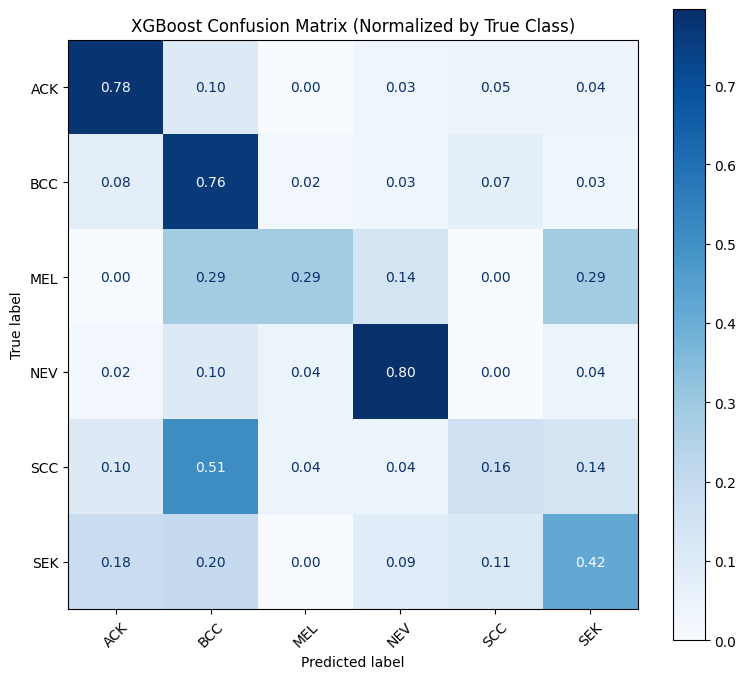

In [32]:
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay
cm_norm = confusion_matrix(y_test, xgb_preds, normalize='true')

fig, ax = plt.subplots(figsize=(8,7))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_norm, display_labels=le.classes_)
disp.plot(ax=ax, cmap='Blues', values_format='.2f')
plt.title('XGBoost Confusion Matrix (Normalized by True Class)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [35]:
import os

def build_image_index(root_dir):
    index = {}
    for dirpath, dirnames, filenames in os.walk(root_dir):
        for fname in filenames:
            if fname.lower().endswith(('.png', '.jpg', '.jpeg')):
                index[fname] = os.path.join(dirpath, fname)
    return index

IMG_ROOT = r"C:\Users\shriy\OneDrive\Documents\summer research\zr7vgbcyr2-1\images"
img_index = build_image_index(IMG_ROOT)

print(len(img_index), "images indexed")
print(data['img_id'].isin(img_index.keys()).sum(), "of", len(data), "metadata rows have a matching image")

2298 images indexed
2298 of 2298 metadata rows have a matching image


In [36]:
from PIL import Image
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

class SkinLesionDataset(Dataset):
    def __init__(self, df, img_index, label_encoder, transform=None):
        self.df = df.reset_index(drop=True)
        self.img_index = img_index
        self.le = label_encoder
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_path = self.img_index[row['img_id']]
        image = Image.open(img_path).convert('RGB')
        label = self.le.transform([row['diagnostic']])[0]
        if self.transform:
            image = self.transform(image)
        return image, label

In [37]:
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

In [38]:
train_img_ds = SkinLesionDataset(train_df, img_index, le, transform=train_transform)
test_img_ds = SkinLesionDataset(test_df, img_index, le, transform=test_transform)

train_img_loader = DataLoader(train_img_ds, batch_size=32, shuffle=True)
test_img_loader = DataLoader(test_img_ds, batch_size=32, shuffle=False)

print(len(train_img_ds), "training images,", len(test_img_ds), "test images")

1837 training images, 461 test images


In [39]:
images, labels = next(iter(train_img_loader))
print("Batch image tensor shape:", images.shape)
print("Batch labels:", labels)

Batch image tensor shape: torch.Size([32, 3, 224, 224])
Batch labels: tensor([4, 4, 5, 1, 3, 5, 3, 5, 0, 0, 5, 0, 0, 0, 1, 3, 4, 1, 1, 4, 3, 5, 4, 0,
        1, 4, 3, 5, 3, 1, 0, 0])


In [41]:
#CNN  MODEL
import torch.nn as nn
import torch.nn.functional as F

class SimpleCNN(nn.Module):
    def __init__(self, num_classes=6):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)

        self.fc1 = nn.Linear(128 * 28 * 28, 256)
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))   # 224 -> 112
        x = self.pool(F.relu(self.conv2(x)))   # 112 -> 56
        x = self.pool(F.relu(self.conv3(x)))   # 56 -> 28
        x = x.view(x.size(0), -1)               # flatten
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        return x

In [42]:
#Computing loss andweighting losses more for lesser sample data
import torch
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

cnn_model = SimpleCNN(num_classes=len(le.classes_)).to(device)

train_labels_arr = train_df['diagnostic'].map(lambda x: le.transform([x])[0]).values
class_weights = compute_class_weight('balanced', classes=np.arange(len(le.classes_)), y=train_labels_arr)
class_weights = torch.tensor(class_weights, dtype=torch.float).to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.Adam(cnn_model.parameters(), lr=1e-4)

In [43]:
num_epochs = 15

for epoch in range(num_epochs):
    cnn_model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_img_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = cnn_model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    print(f"Epoch {epoch+1}/{num_epochs} - Loss: {epoch_loss:.4f} - Train Accuracy: {epoch_acc:.4f}")

Epoch 1/15 - Loss: 1.7890 - Train Accuracy: 0.2324
Epoch 2/15 - Loss: 1.6395 - Train Accuracy: 0.3125
Epoch 3/15 - Loss: 1.5818 - Train Accuracy: 0.3348
Epoch 4/15 - Loss: 1.5173 - Train Accuracy: 0.3065
Epoch 5/15 - Loss: 1.4812 - Train Accuracy: 0.3838
Epoch 6/15 - Loss: 1.4293 - Train Accuracy: 0.3930
Epoch 7/15 - Loss: 1.4183 - Train Accuracy: 0.4251
Epoch 8/15 - Loss: 1.3766 - Train Accuracy: 0.4208
Epoch 9/15 - Loss: 1.3557 - Train Accuracy: 0.4360
Epoch 10/15 - Loss: 1.3263 - Train Accuracy: 0.4426
Epoch 11/15 - Loss: 1.3194 - Train Accuracy: 0.4475
Epoch 12/15 - Loss: 1.2929 - Train Accuracy: 0.4616
Epoch 13/15 - Loss: 1.2750 - Train Accuracy: 0.4867
Epoch 14/15 - Loss: 1.2379 - Train Accuracy: 0.4589
Epoch 15/15 - Loss: 1.2505 - Train Accuracy: 0.4540


In [44]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

cnn_model.eval()   # switches off dropout — you want the model's full capacity when just predicting, not training
all_preds = []
all_labels = []

with torch.no_grad():   # tells PyTorch not to track gradients — saves memory/time since we're not training here
    for images, labels in test_img_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = cnn_model(images)
        _, predicted = torch.max(outputs, 1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

print(classification_report(all_labels, all_preds, target_names=le.classes_))
print(confusion_matrix(all_labels, all_preds))

              precision    recall  f1-score   support

         ACK       0.55      0.61      0.57       127
         BCC       0.66      0.53      0.59       174
         MEL       0.17      0.43      0.24         7
         NEV       0.49      0.47      0.48        49
         SCC       0.21      0.24      0.23        49
         SEK       0.47      0.49      0.48        55

    accuracy                           0.51       461
   macro avg       0.42      0.46      0.43       461
weighted avg       0.53      0.51      0.52       461

[[77 19  0  8  9 14]
 [32 92  2  4 34 10]
 [ 0  1  3  1  0  2]
 [ 6  7 10 23  2  1]
 [10 21  0  2 12  4]
 [16  0  3  9  0 27]]


In [45]:
from torchvision import models
import torch.nn as nn

efficientnet_model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)

# freeze everything - we don't want to retrain the pretrained vision knowledge
for param in efficientnet_model.parameters():
    param.requires_grad = False

# EfficientNet's final layer currently outputs 1000 ImageNet classes - swap it for your 6
num_features = efficientnet_model.classifier[1].in_features
efficientnet_model.classifier[1] = nn.Linear(num_features, len(le.classes_))

efficientnet_model = efficientnet_model.to(device)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to C:\Users\shriy/.cache\torch\hub\checkpoints\efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:07<00:00, 3.05MB/s]


In [46]:
criterion_eff = nn.CrossEntropyLoss(weight=class_weights)
optimizer_eff = torch.optim.Adam(efficientnet_model.classifier.parameters(), lr=1e-4)

In [47]:
num_epochs_eff = 15

for epoch in range(num_epochs_eff):
    efficientnet_model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_img_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer_eff.zero_grad()
        outputs = efficientnet_model(images)
        loss = criterion_eff(outputs, labels)
        loss.backward()
        optimizer_eff.step()

        running_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    print(f"Epoch {epoch+1}/{num_epochs_eff} - Loss: {epoch_loss:.4f} - Train Accuracy: {epoch_acc:.4f}")

Epoch 1/15 - Loss: 1.7686 - Train Accuracy: 0.2667
Epoch 2/15 - Loss: 1.7014 - Train Accuracy: 0.3527
Epoch 3/15 - Loss: 1.6468 - Train Accuracy: 0.4257
Epoch 4/15 - Loss: 1.6060 - Train Accuracy: 0.4480
Epoch 5/15 - Loss: 1.5555 - Train Accuracy: 0.4627
Epoch 6/15 - Loss: 1.5353 - Train Accuracy: 0.4834
Epoch 7/15 - Loss: 1.4920 - Train Accuracy: 0.5133
Epoch 8/15 - Loss: 1.4688 - Train Accuracy: 0.5226
Epoch 9/15 - Loss: 1.4334 - Train Accuracy: 0.5112
Epoch 10/15 - Loss: 1.4128 - Train Accuracy: 0.5128
Epoch 11/15 - Loss: 1.3992 - Train Accuracy: 0.5324
Epoch 12/15 - Loss: 1.3696 - Train Accuracy: 0.5269
Epoch 13/15 - Loss: 1.3580 - Train Accuracy: 0.5580
Epoch 14/15 - Loss: 1.3339 - Train Accuracy: 0.5645
Epoch 15/15 - Loss: 1.3169 - Train Accuracy: 0.5460


In [48]:
from sklearn.metrics import classification_report, confusion_matrix

efficientnet_model.eval()
all_preds_eff = []
all_labels_eff = []

with torch.no_grad():
    for images, labels in test_img_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = efficientnet_model(images)
        _, predicted = torch.max(outputs, 1)
        all_preds_eff.extend(predicted.cpu().numpy())
        all_labels_eff.extend(labels.cpu().numpy())

print(classification_report(all_labels_eff, all_preds_eff, target_names=le.classes_))
print(confusion_matrix(all_labels_eff, all_preds_eff))

              precision    recall  f1-score   support

         ACK       0.57      0.54      0.55       127
         BCC       0.64      0.51      0.57       174
         MEL       0.33      0.57      0.42         7
         NEV       0.50      0.76      0.60        49
         SCC       0.20      0.27      0.23        49
         SEK       0.48      0.45      0.47        55

    accuracy                           0.51       461
   macro avg       0.45      0.52      0.47       461
weighted avg       0.53      0.51      0.52       461

[[68 22  0  7 16 14]
 [32 89  5 11 30  7]
 [ 2  1  4  0  0  0]
 [ 2  5  1 37  1  3]
 [ 9 19  0  5 13  3]
 [ 7  3  2 14  4 25]]


In [49]:
from torchvision import models

vit_model = models.vit_b_16(weights=models.ViT_B_16_Weights.IMAGENET1K_V1)

# freeze everything, same reasoning as EfficientNet - keep the pretrained vision knowledge intact
for param in vit_model.parameters():
    param.requires_grad = False

# ViT's final layer is called 'heads', not 'classifier' like EfficientNet - swap it for your 6 classes
num_features = vit_model.heads.head.in_features
vit_model.heads.head = nn.Linear(num_features, len(le.classes_))

vit_model = vit_model.to(device)

Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to C:\Users\shriy/.cache\torch\hub\checkpoints\vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:34<00:00, 10.2MB/s] 


In [50]:
criterion_vit = nn.CrossEntropyLoss(weight=class_weights)
optimizer_vit = torch.optim.Adam(vit_model.heads.parameters(), lr=1e-4)

In [53]:
num_epochs_vit = 15

for epoch in range(num_epochs_vit):
    vit_model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_img_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer_vit.zero_grad()
        outputs = vit_model(images)
        loss = criterion_vit(outputs, labels)
        loss.backward()
        optimizer_vit.step()

        running_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    print(f"Epoch {epoch+1}/{num_epochs_vit} - Loss: {epoch_loss:.4f} - Train Accuracy: {epoch_acc:.4f}")

Epoch 1/15 - Loss: 1.7404 - Train Accuracy: 0.2972
Epoch 2/15 - Loss: 1.6175 - Train Accuracy: 0.4333


KeyboardInterrupt: 